# CodeAlpha ML Internship — Task 2: Emotion Recognition from Speech

**Objective:** recognise human emotions (happy, angry, sad, ...) from speech audio.

**Approach:** speech signal processing (MFCC features) + deep learning (**CNN** and **bidirectional LSTM**), compared with a classical SVM / Random Forest baseline.

**Dataset:** a subset of **RAVDESS** — the *Ryerson Audio-Visual Database of Emotional Speech and Song* (Livingstone & Russo, 2018, CC BY-NC-SA 4.0). Stored in `data/RAVDESS_Actors_01-06/`:
**360 speech clips from 6 professional actors (3 male, 3 female)**, 16 kHz, ~3.7 s each, 8 emotions.

| code | emotion | clips | | code | emotion | clips |
|---|---|---|---|---|---|---|
| 01 | neutral | 24 | | 05 | angry | 48 |
| 02 | calm | 48 | | 06 | fearful | 48 |
| 03 | happy | 48 | | 07 | disgust | 48 |
| 04 | sad | 48 | | 08 | surprised | 48 |

Each file name encodes its label: `03-01-EMOTION-INTENSITY-STATEMENT-REPETITION-ACTOR.wav`.

### Evaluation design (important)
With only 360 clips, a random train/test split would put the *same actor* in both sets and the model would partly learn to recognise voices instead of emotions, giving over-optimistic scores. We therefore use **speaker-independent 3-fold cross-validation**: in each fold two complete actors are held out for testing and the model never hears them during training. Augmentation (noise, pitch shift, time stretch) is applied to **training clips only**.

> A full RAVDESS download has 24 actors / 1,440 speech clips and would raise accuracy; the notebook picks up any additional `Actor_XX` folders automatically.

In [1]:
import os, re, glob, warnings, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display
import soundfile as sf
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
SR = 16000

I0000 00:00:1793133769.436402   20405 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793133770.634836   20405 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Build the metadata table

In [2]:
EMOTIONS = {"01": "neutral", "02": "calm", "03": "happy", "04": "sad", "05": "angry", "06": "fearful", "07": "disgust", "08": "surprised"}

rows = []
for path in sorted(glob.glob("data/RAVDESS_Actors_*/Actor_*/*.wav")):
    p = os.path.basename(path)[:-4].split("-")
    if len(p) != 7 or p[0] != "03" or p[1] != "01":      # audio-only + speech
        continue
    rows.append({"path": path, "emotion": EMOTIONS[p[2]], "intensity": "normal" if p[3] == "01" else "strong",
                 "statement": p[4], "actor": int(p[6]), "gender": "male" if int(p[6]) % 2 else "female"})
meta = pd.DataFrame(rows)
print(len(meta), "clips |", meta["actor"].nunique(), "actors")
display(pd.crosstab(meta["emotion"], meta["actor"], margins=True))
meta.head()

360 clips | 6 actors


actor,1,2,3,4,5,6,All
emotion,,,,,,,
angry,8,8,8,8,8,8,48
calm,8,8,8,8,8,8,48
disgust,8,8,8,8,8,8,48
fearful,8,8,8,8,8,8,48
happy,8,8,8,8,8,8,48
neutral,4,4,4,4,4,4,24
sad,8,8,8,8,8,8,48
surprised,8,8,8,8,8,8,48
All,60,60,60,60,60,60,360


,path,emotion,intensity,statement,actor,gender
0,data/RAVDESS_Actors_01-06/Actor_01/03-01-01-01...,neutral,normal,01,1,male
1,data/RAVDESS_Actors_01-06/Actor_01/03-01-01-01...,neutral,normal,01,1,male
2,data/RAVDESS_Actors_01-06/Actor_01/03-01-01-01...,neutral,normal,02,1,male
3,data/RAVDESS_Actors_01-06/Actor_01/03-01-01-01...,neutral,normal,02,1,male
4,data/RAVDESS_Actors_01-06/Actor_01/03-01-02-01...,calm,normal,01,1,male


## 2. Listen to the signal: waveforms, spectrograms and MFCCs

Emotions change **pitch, loudness, speaking rate and timbre** — all visible in the spectrogram. MFCCs summarise the spectral envelope on the perceptual (mel) scale and are the classic feature for speech tasks.

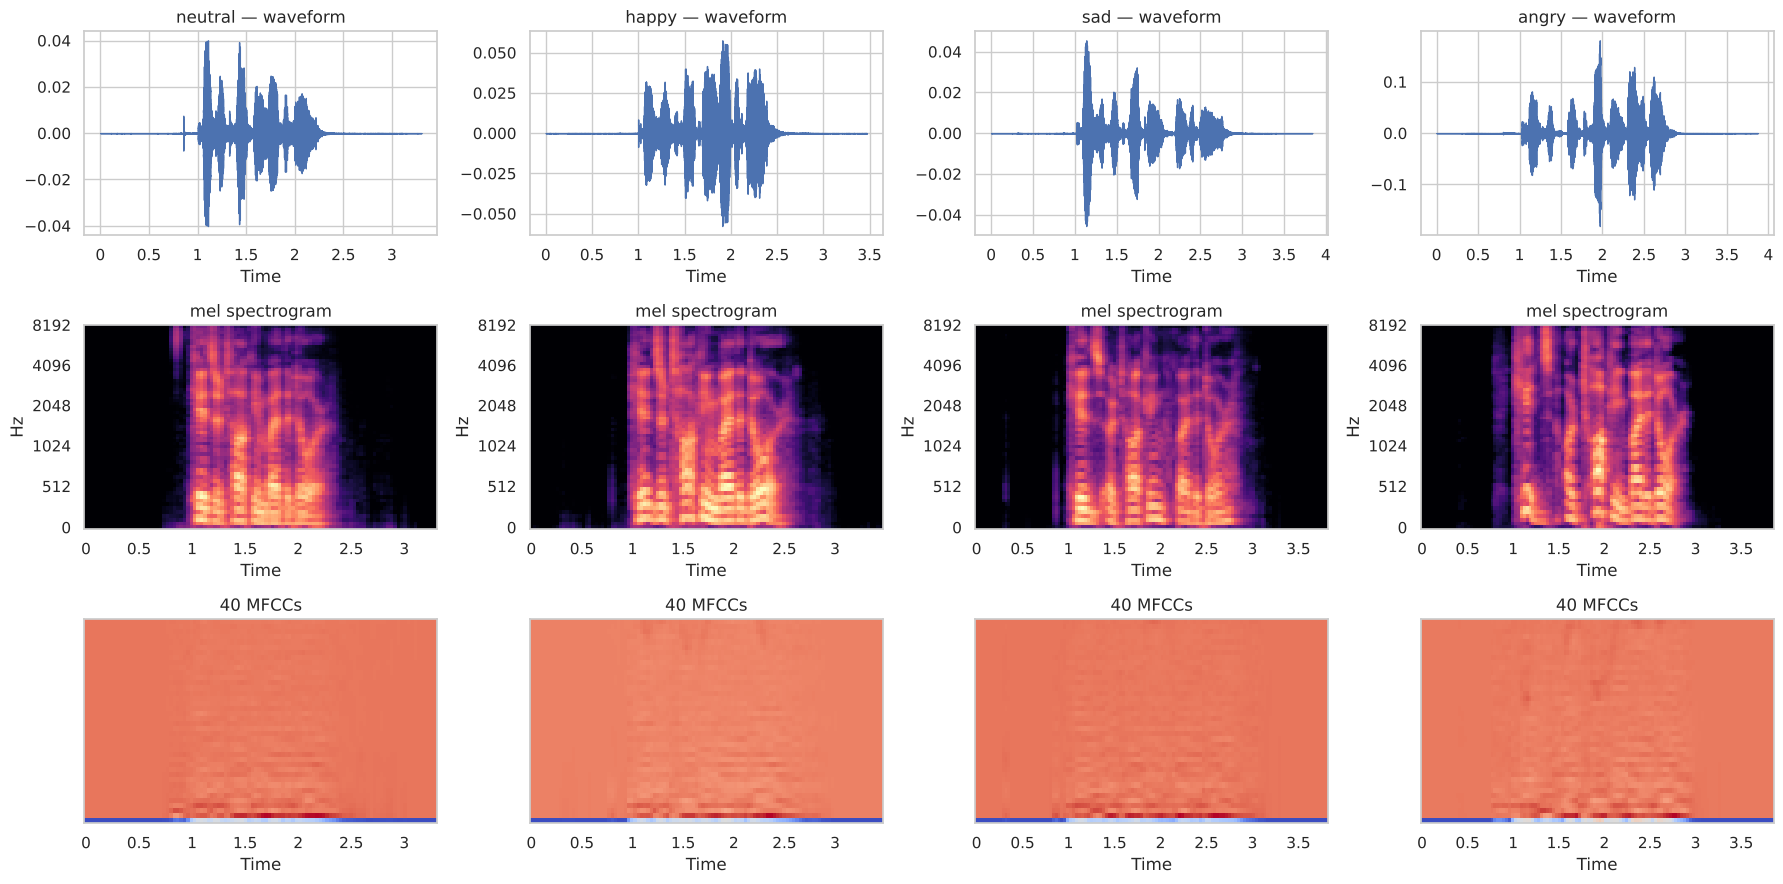

In [3]:
demo_emotions = ["neutral", "happy", "sad", "angry"]
fig, axes = plt.subplots(3, 4, figsize=(18, 9))
for j, emo in enumerate(demo_emotions):
    r = meta[(meta.emotion == emo) & (meta.actor == 1) & (meta.statement == "01")].iloc[0]
    y, _ = librosa.load(r.path, sr=SR)
    librosa.display.waveshow(y, sr=SR, ax=axes[0, j], color="#4C72B0"); axes[0, j].set_title(f"{emo} — waveform")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="mel", ax=axes[1, j], cmap="magma"); axes[1, j].set_title("mel spectrogram")
    M = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=40)
    librosa.display.specshow(M, sr=SR, x_axis="time", ax=axes[2, j], cmap="coolwarm"); axes[2, j].set_title("40 MFCCs")
plt.tight_layout(); plt.show()

## 3. Feature extraction

Two representations are built from every clip:

1. **Sequence features** `(time, 123)` for the CNN and LSTM: 40 MFCCs + 40 delta + 40 delta-delta, plus RMS energy, zero-crossing rate and spectral centroid per frame — padded/trimmed to 200 frames (~3.2 s at hop 256).
2. **Utterance-level statistics** (mean and standard deviation of every frame feature → 246 numbers) for the classical SVM / Random Forest baselines.

**Augmentation** (training clips only): additive Gaussian noise, pitch shift (±2 semitones) and time stretch (0.9× / 1.1×) — each original clip yields two extra variants, which matters a lot with so little data.

In [4]:
N_MFCC, HOP, T_FRAMES = 40, 256, 200

def frame_features(y: np.ndarray) -> np.ndarray:
    y, _ = librosa.effects.trim(y, top_db=30)
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, n_fft=512, hop_length=HOP)
    d1, d2 = librosa.feature.delta(mfcc), librosa.feature.delta(mfcc, order=2)
    rms = librosa.feature.rms(y=y, frame_length=512, hop_length=HOP)
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=512, hop_length=HOP)
    cen = librosa.feature.spectral_centroid(y=y, sr=SR, n_fft=512, hop_length=HOP) / (SR / 2)
    return np.vstack([mfcc, d1, d2, rms, zcr, cen]).T.astype("float32")          # (frames, 123)

def pad_trunc(F: np.ndarray, T=T_FRAMES) -> np.ndarray:
    if len(F) >= T:
        return F[:T]
    return np.vstack([F, np.zeros((T - len(F), F.shape[1]), dtype="float32")])

def utterance_stats(F: np.ndarray) -> np.ndarray:
    return np.concatenate([F.mean(axis=0), F.std(axis=0)])

def augment(y: np.ndarray, kind: str, rng) -> np.ndarray:
    if kind == "noise":
        return y + rng.normal(0, 0.005 + 0.01 * rng.random(), size=y.shape).astype(y.dtype) * max(np.abs(y).max(), 1e-3) * 5
    if kind == "pitch":
        return librosa.effects.pitch_shift(y, sr=SR, n_steps=rng.choice([-2, -1, 1, 2]))
    if kind == "stretch":
        return librosa.effects.time_stretch(y, rate=rng.choice([0.9, 1.1]))
    raise ValueError(kind)

rng = np.random.default_rng(SEED)
t0 = time.time()
seq_orig, seq_aug, aug_owner = [], [], []
for i, path in enumerate(meta["path"]):
    y, _ = librosa.load(path, sr=SR)
    seq_orig.append(pad_trunc(frame_features(y)))
    for kind in rng.choice(["noise", "pitch", "stretch"], size=2, replace=False):
        seq_aug.append(pad_trunc(frame_features(augment(y, kind, rng)))); aug_owner.append(i)

X_orig = np.stack(seq_orig); X_aug = np.stack(seq_aug); aug_owner = np.array(aug_owner)
le = LabelEncoder().fit(meta["emotion"])
y_all = le.transform(meta["emotion"]); CLASSES = list(le.classes_)
actors = meta["actor"].values
print(f"original {X_orig.shape}, augmented {X_aug.shape}   ({time.time() - t0:.0f}s)")
print("classes:", CLASSES)

original (360, 200, 123), augmented (720, 200, 123)   (13s)
classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']


## 4. Speaker-independent cross-validation folds

The six actors are paired so that each fold tests on one male and one female voice that the model has never heard.

In [5]:
ALL_ACTORS = sorted(meta["actor"].unique())
# pair actors (1,2), (3,4), (5,6) ... -> every fold holds out one man and one woman
FOLDS = [tuple(ALL_ACTORS[i:i + 2]) for i in range(0, len(ALL_ACTORS) - len(ALL_ACTORS) % 2, 2)]
print("Held-out actors per fold:", FOLDS)

def fold_indices(test_actors):
    test_mask = np.isin(actors, test_actors)
    tr = np.where(~test_mask)[0]; te = np.where(test_mask)[0]
    aug_idx = np.where(~np.isin(actors[aug_owner], test_actors))[0]          # augmentations of training clips only
    return tr, te, aug_idx

Held-out actors per fold: [(np.int64(1), np.int64(2)), (np.int64(3), np.int64(4)), (np.int64(5), np.int64(6))]


## 5. Baselines: SVM and Random Forest on utterance statistics

In [6]:
def stats_matrix(X):                               # (n, T, 123) -> (n, 246), ignoring zero padding
    out = []
    for seq in X:
        valid = np.abs(seq).sum(axis=1) > 0
        out.append(utterance_stats(seq[valid] if valid.any() else seq))
    return np.stack(out)

S_orig, S_aug = stats_matrix(X_orig), stats_matrix(X_aug)

baseline_rows, baseline_pred = [], {"SVM (RBF)": np.zeros(len(y_all), int), "Random Forest": np.zeros(len(y_all), int)}
for fold, test_actors in enumerate(FOLDS, 1):
    tr, te, aug_idx = fold_indices(test_actors)
    Xtr = np.vstack([S_orig[tr], S_aug[aug_idx]]); ytr = np.concatenate([y_all[tr], y_all[aug_owner[aug_idx]]])
    sc = StandardScaler().fit(Xtr)
    for name, clf in {"SVM (RBF)": SVC(C=10, gamma="scale", random_state=SEED),
                      "Random Forest": RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=SEED)}.items():
        clf.fit(sc.transform(Xtr), ytr)
        p = clf.predict(sc.transform(S_orig[te])); baseline_pred[name][te] = p
        baseline_rows.append({"fold": fold, "model": name, "accuracy": accuracy_score(y_all[te], p),
                              "macro_F1": f1_score(y_all[te], p, average="macro")})
baseline_df = pd.DataFrame(baseline_rows)
baseline_df.pivot(index="model", columns="fold", values="accuracy").assign(mean=lambda d: d.mean(axis=1)).round(3)

fold,1,2,3,mean
model,,,,
Random Forest,0.325,0.417,0.425,0.389
SVM (RBF),0.400,0.417,0.467,0.428


## 6. Deep models

* **CNN** – a 1-D convolutional network over time: the filters slide along the time axis across all 123 acoustic channels and learn short patterns such as pitch rises or energy bursts; global average + max pooling then summarise the whole utterance.
* **BiLSTM** – reads the clip frame by frame in both directions and keeps a memory of how the voice evolves over the sentence; mean + max pooling over its outputs gives the utterance representation.

Because there are only 4 training actors per fold, both networks are deliberately **small and regularised** (dropout, weight decay; a larger CNN with L2 + masking was tried during development and did clearly worse). Inputs get a per-utterance *cepstral mean subtraction* of the MFCC channels (removes speaker / microphone colouring) followed by feature-wise standardisation fitted on the training fold. All four training actors are used for fitting, with a fixed number of epochs and a learning-rate decay, so no precious speaker is spent on validation.

In [7]:
n_feat = X_orig.shape[2]
NUM_CLASSES = len(CLASSES)

def build_cnn():
    inp = keras.Input(shape=(T_FRAMES, n_feat))
    x = inp
    for f in (32, 64, 64):
        x = layers.Conv1D(f, 5, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x); x = layers.Activation("relu")(x)
        x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.4)(x)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), layers.GlobalMaxPooling1D()(x)])
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="cnn1d")

def build_bilstm():
    inp = keras.Input(shape=(T_FRAMES, n_feat))
    x = layers.SpatialDropout1D(0.1)(inp)
    x = layers.Conv1D(48, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.LSTM(48, return_sequences=True, dropout=0.2, recurrent_dropout=0.0))(x)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), layers.GlobalMaxPooling1D()(x)])
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(48, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3))(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="bilstm")

BUILDERS = {"CNN": build_cnn, "BiLSTM": build_bilstm}
BUILDERS["CNN"]().summary()

Model: "cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200, 123)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 200, 32)   │     19,680 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 200, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 200, 32)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 100, 32)   │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 100, 32)   │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 100, 64)   │     10,240 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 100, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 50, 64)    │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 50, 64)    │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 50, 64)    │     20,480 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 50, 64)    │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 50, 64)    │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 25, 64)    │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 25, 64)    │          0 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ dropout_2[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ dropout_2[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ global_average_p

 Total params: 59,816 (233.66 KB)

 Trainable params: 59,496 (232.41 KB)

 Non-trainable params: 320 (1.25 KB)

In [8]:
N_CEPSTRAL = 3 * N_MFCC          # first 120 channels are MFCC + deltas

def cepstral_mean_subtraction(X):
    # per-utterance mean subtraction of the MFCC channels (ignores zero padding)
    X = X.copy()
    valid = (np.abs(X).sum(axis=2) > 0)
    for i in range(len(X)):
        v = valid[i]
        X[i, v, :N_CEPSTRAL] -= X[i, v, :N_CEPSTRAL].mean(axis=0)
    return X * valid[..., None]

EPOCHS = 40

def fit_normaliser(X_train_raw):
    Z = cepstral_mean_subtraction(X_train_raw)
    return Z.reshape(-1, n_feat).mean(axis=0), Z.reshape(-1, n_feat).std(axis=0) + 1e-6

def apply_normaliser(X_raw, mu, sd):
    Z = cepstral_mean_subtraction(X_raw)
    return ((Z - mu) / sd) * (np.abs(X_raw).sum(axis=2, keepdims=True) > 0)

def compile_model(model_name):
    model = BUILDERS[model_name]()
    if model_name == "CNN":
        opt = keras.optimizers.Adam(1e-3)
    else:                                                    # the recurrent model benefits from decay + weight decay
        opt = keras.optimizers.AdamW(keras.optimizers.schedules.CosineDecay(2e-3, decay_steps=EPOCHS * 30, alpha=0.05), weight_decay=1e-3)
    model.compile(optimizer=opt, loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
    return model

def train_fold(model_name, test_actors, epochs=EPOCHS, verbose=0):
    tr, te, aug_idx = fold_indices(test_actors)
    Xtr_raw = np.concatenate([X_orig[tr], X_aug[aug_idx]]); ytr = np.concatenate([y_all[tr], y_all[aug_owner[aug_idx]]])
    mu, sd = fit_normaliser(Xtr_raw)
    model = compile_model(model_name)
    hist = model.fit(apply_normaliser(Xtr_raw, mu, sd), ytr, epochs=epochs, batch_size=32, verbose=verbose)
    proba = model.predict(apply_normaliser(X_orig[te], mu, sd), verbose=0)
    return te, proba, hist.history, epochs

deep_pred = {m: np.zeros(len(y_all), int) for m in BUILDERS}
deep_hist, deep_rows = {m: [] for m in BUILDERS}, []
for model_name in BUILDERS:
    for fold, test_actors in enumerate(FOLDS, 1):
        t0 = time.time()
        te, proba, hist, n_ep = train_fold(model_name, test_actors)
        pred = proba.argmax(axis=1); deep_pred[model_name][te] = pred; deep_hist[model_name].append(hist)
        acc = accuracy_score(y_all[te], pred)
        deep_rows.append({"fold": fold, "model": model_name, "accuracy": acc, "macro_F1": f1_score(y_all[te], pred, average="macro")})
        print(f"{model_name:7s} fold {fold} (held-out actors {test_actors}): accuracy {acc:.3f}  [{n_ep} epochs, {time.time() - t0:.0f}s]")
deep_df = pd.DataFrame(deep_rows)

CNN     fold 1 (held-out actors (np.int64(1), np.int64(2))): accuracy 0.342  [40 epochs, 21s]


CNN     fold 2 (held-out actors (np.int64(3), np.int64(4))): accuracy 0.275  [40 epochs, 22s]


CNN     fold 3 (held-out actors (np.int64(5), np.int64(6))): accuracy 0.358  [40 epochs, 21s]


BiLSTM  fold 1 (held-out actors (np.int64(1), np.int64(2))): accuracy 0.467  [40 epochs, 49s]


BiLSTM  fold 2 (held-out actors (np.int64(3), np.int64(4))): accuracy 0.417  [40 epochs, 51s]


BiLSTM  fold 3 (held-out actors (np.int64(5), np.int64(6))): accuracy 0.450  [40 epochs, 49s]


## 7. Results

Chance level with 8 classes = 0.125


,accuracy,accuracy_std,macro_F1
model,,,
BiLSTM,0.444,0.025,0.431
SVM (RBF),0.428,0.035,0.383
Random Forest,0.389,0.055,0.349
CNN,0.325,0.044,0.294


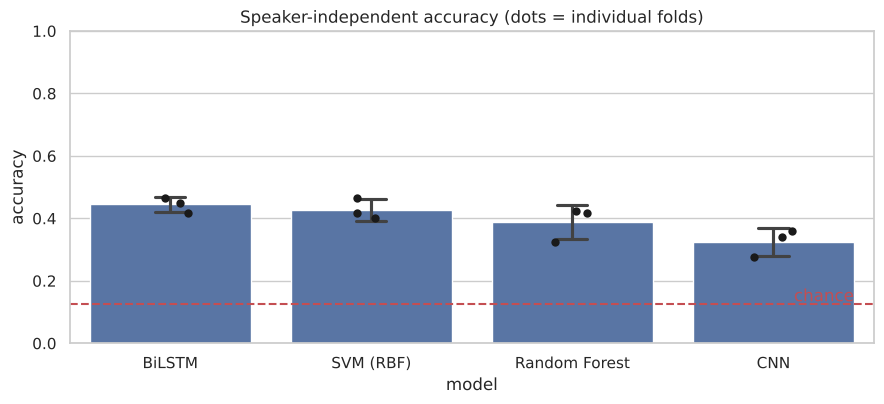

In [9]:
all_df = pd.concat([baseline_df, deep_df])
summary = all_df.groupby("model").agg(accuracy=("accuracy", "mean"), accuracy_std=("accuracy", "std"), macro_F1=("macro_F1", "mean")).round(3)
summary = summary.sort_values("accuracy", ascending=False)
print(f"Chance level with 8 classes = {1 / NUM_CLASSES:.3f}")
display(summary)

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(data=all_df, x="model", y="accuracy", order=summary.index, errorbar="sd", color="#4C72B0", ax=ax, capsize=.15)
sns.stripplot(data=all_df, x="model", y="accuracy", order=summary.index, color="k", size=6, ax=ax)
ax.axhline(1 / NUM_CLASSES, ls="--", c="#C44E52"); ax.text(3.4, 1 / NUM_CLASSES + .01, "chance", color="#C44E52", ha="right")
ax.set_ylim(0, 1); ax.set_title("Speaker-independent accuracy (dots = individual folds)"); plt.tight_layout(); plt.show()

Best model: BiLSTM 

              precision    recall  f1-score   support

       angry      0.667     0.458     0.543        48
        calm      0.591     0.542     0.565        48
     disgust      0.429     0.500     0.462        48
     fearful      0.468     0.458     0.463        48
       happy      0.333     0.333     0.333        48
     neutral      0.257     0.375     0.305        24
         sad      0.275     0.229     0.250        48
   surprised      0.526     0.625     0.571        48

    accuracy                          0.444       360
   macro avg      0.443     0.440     0.437       360
weighted avg      0.456     0.444     0.445       360



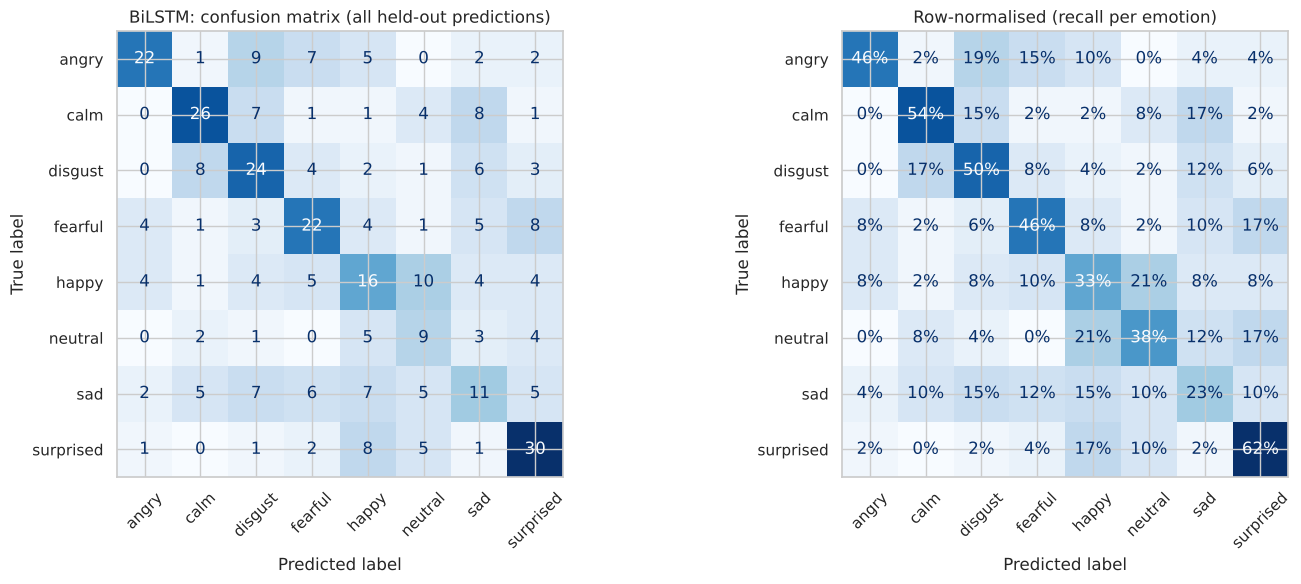

In [10]:
best_model = summary.index[0]
all_preds = {**baseline_pred, **deep_pred}
print("Best model:", best_model, "\n")
print(classification_report(y_all, all_preds[best_model], target_names=CLASSES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay.from_predictions(y_all, all_preds[best_model], display_labels=CLASSES, cmap="Blues", colorbar=False, ax=axes[0], xticks_rotation=45)
axes[0].set_title(f"{best_model}: confusion matrix (all held-out predictions)")
ConfusionMatrixDisplay.from_predictions(y_all, all_preds[best_model], display_labels=CLASSES, cmap="Blues", colorbar=False,
                                        normalize="true", values_format=".0%", ax=axes[1], xticks_rotation=45)
axes[1].set_title("Row-normalised (recall per emotion)")
plt.tight_layout(); plt.show()

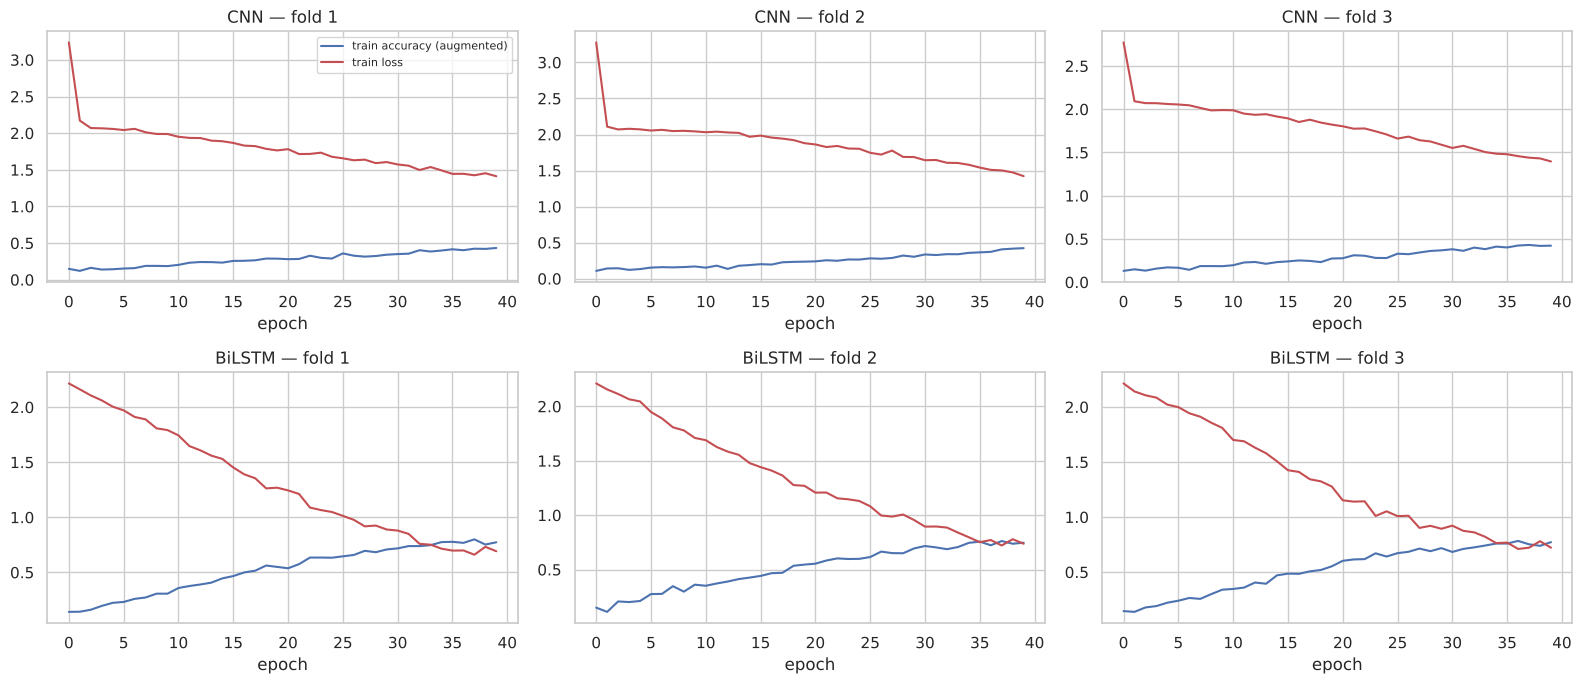

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey=False)
for r, model_name in enumerate(BUILDERS):
    for c, h in enumerate(deep_hist[model_name]):
        axes[r, c].plot(h["accuracy"], label="train accuracy (augmented)", color="#4C72B0")
        axes[r, c].plot(h["loss"], label="train loss", color="#C44E52")
        axes[r, c].set_title(f"{model_name} — fold {c + 1}"); axes[r, c].set_xlabel("epoch")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Final model and prediction on a new recording

For deployment we train the better of the two deep architectures on **all** actors (same fixed number of epochs, with augmentation) and wrap everything in `predict_emotion(path)`, which loads any audio file, resamples it to 16 kHz and returns the probability of each emotion. Because every demo clip below comes from the training pool, treat that as a functionality check, not as a performance estimate — the cross-validated numbers above are the honest ones.

Deep architecture used for the final model: BiLSTM


True emotion: neutral | file: 03-01-01-01-01-01-02.wav


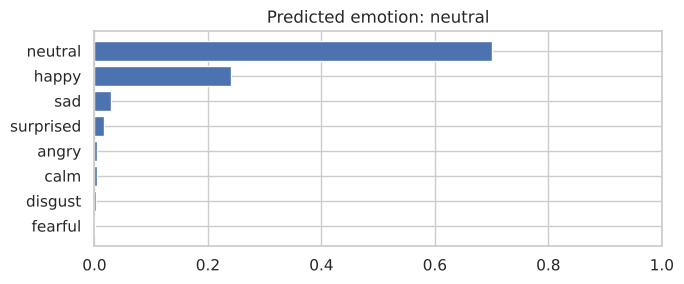

{'neutral': np.float32(0.701), 'happy': np.float32(0.241), 'sad': np.float32(0.03), 'surprised': np.float32(0.017), 'angry': np.float32(0.005), 'calm': np.float32(0.004), 'disgust': np.float32(0.003), 'fearful': np.float32(0.001)}


In [12]:
deep_best = max(BUILDERS, key=lambda m: summary.loc[m, "accuracy"])
print("Deep architecture used for the final model:", deep_best)

Xfull = np.concatenate([X_orig, X_aug]); yfull = np.concatenate([y_all, y_all[aug_owner]])
MU, SD = fit_normaliser(Xfull)
_prep_final = lambda X: apply_normaliser(X, MU, SD)

final_model = compile_model(deep_best)
final_model.fit(_prep_final(Xfull), yfull, epochs=EPOCHS, batch_size=32, verbose=0)

def predict_emotion(path, show=True):
    y, _ = librosa.load(path, sr=SR)
    x = pad_trunc(frame_features(y))[None]
    p = final_model.predict(_prep_final(x), verbose=0)[0]
    result = dict(sorted(zip(CLASSES, p.round(3)), key=lambda kv: -kv[1]))
    if show:
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.barh(list(result.keys())[::-1], list(result.values())[::-1], color="#4C72B0"); ax.set_xlim(0, 1)
        ax.set_title(f"Predicted emotion: {next(iter(result))}"); plt.tight_layout(); plt.show()
    return result

sample = meta.sample(1, random_state=7).iloc[0]
print("True emotion:", sample.emotion, "| file:", os.path.basename(sample.path))
print(predict_emotion(sample.path))

In [13]:
os.makedirs("outputs", exist_ok=True)
final_model.save("outputs/emotion_" + deep_best.lower() + ".keras")
np.savez("outputs/normalisation.npz", mu=MU, sd=SD, classes=np.array(CLASSES))
print("Saved model + normalisation statistics to ./outputs")

Saved model + normalisation statistics to ./outputs


## 9. Conclusion

* Speaker-independent emotion recognition on 8 classes is **hard**. Our best model (the BiLSTM) reaches roughly **44 % accuracy / 0.44 macro-F1 — more than 3× the 12.5 % chance level**, ahead of the SVM baseline (~43 %), the Random Forest (~39 %) and the 1-D CNN (~33 %). The differences between the top models are within one standard deviation across folds (3 folds × 2 actors), so the honest reading is: *the BiLSTM and SVM are comparable, the CNN is clearly weaker with this little data.*
* These numbers are far below the 90 %+ figures often quoted for RAVDESS because those usually come from random splits where the same actor appears in train and test. Speaker-independent scores are the realistic ones.
* Per-emotion results (classification report and confusion matrix above) show that **calm, surprised, angry, disgust and fearful** are recognised best, while **sad, neutral and happy** are the most confused — neutral and calm sound alike, and several clips of different emotions share the same flat delivery.
* The data is the main bottleneck: each fold trains on only 4 voices (240 clips + augmented copies). Heavier networks overfit quickly; in development a larger CNN with L2 regularisation and masking scored clearly lower than the small one used here.

**How to improve:** use all 24 RAVDESS actors (drop their folders next to the existing ones — the notebook picks them up automatically) and combine with TESS / EMO-DB, add SpecAugment, and try pretrained speech encoders such as wav2vec 2.0 or HuBERT.